# T3. What Filter Has Mamba Learned?

학습된 selective Mamba가 입력마다 적용하는 effective kernel을 정의하고, UCI HAR validation window에서 계산해 class별로 비교합니다.

| 과제 minimum scope | 이 노트북 |
|---|---|
| 1. hidden-attention 형태로 effective SSM-layer kernel 정의 | §1 |
| 2. LTI variant로 `lti_kernel`과 일치하는지 검증 | §2 |
| 3. selective model에 HAR 적용 | §3 |
| 4. 2개 이상 activity class의 class-averaged spectra 비교 (6개 class 모두) | §4 |
| 5. 시간·example에 걸친 요약 방법을 정확히 기술 | §4 첫머리 |
| 확장: Jacobian 기반 whole-block kernel과 hidden-attention의 비교 | §5 |

- validation window만 사용하고 official test set은 읽지 않습니다. seed 0, 1, 2의 체크포인트를 씁니다.
- 결과는 **"Mamba의 frequency response"가 아니라 입력에 조건부인 요약(conditional summary)**입니다.
- 정의, 유도, 결과 정리는 `T3_report.pdf`에 있습니다.

In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent                      # 이 notebook은 effective_kernel/ 폴더에서 실행
sys.path[:0] = [str(ROOT / "mamba_starter"), str(ROOT / "effective_kernel")]
from evaluate import load_checkpoint, evaluation_data
from effective_kernel import effective_kernels
import spectra, jacobian, plots
import check_effective_kernel as chk

SEEDS = [0, 1, 2]
RESULTS = ROOT / "results" / "t3"             # run_t3.py의 결과(전체 validation window). 없으면 아래에서 일부 window로 직접 계산
MAX_PER_CLASS = 30                            # results/t3가 없어서 직접 계산할 때 class당 window 수
device = "cuda" if torch.cuda.is_available() else "cpu"

def load(name, seed):
    model, ckpt = load_checkpoint(ROOT / "checkpoints" / name / f"seed_{seed}" / "best.pt", device)
    x, y = evaluation_data(ckpt, data_root=str(ROOT / "data" / "har"))       # validation window만
    return model, x, np.asarray(y)

model, x, y = load("mamba_selective", 0)
print("validation windows:", x.shape, "| per class:", np.bincount(y), "|", plots.CLASSES)

validation windows: (1960, 128, 9) | per class: [311 280 261 354 374 380] | ['WALKING', 'UPSTAIRS', 'DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


## 1. 정의: effective kernel (hidden-attention 형태)

한 window, 한 layer, SSM 채널 하나에서 SSM은 인과적 선형 사상 $y = Kx$입니다 (Ali et al. 2024, 식 (12)의 형태).

$$K[i,j] = \sum_{m=1}^{N} C_i[m]\, \exp\!\Big(A[m,m] \sum_{k=j+1}^{i} \Delta_k\Big)\, \Delta_j\, B_j[m] \;+\; \mathbf{1}[i=j]\, D \quad (j \le i), \qquad K[i,j] = 0 \quad (j > i)$$

행 $i$는 출력 시점, 열 $j$는 입력 시점입니다. 입력 $x$(코드의 `u`, SSM 채널 64개)는 센서 신호가 아니라 block 안에서 RMSNorm → `in_proj` → causal `conv1d` → SiLU를 거친 값이고, 출력은 gate를 곱하기 전의 SSM 출력입니다. `K[window, layer, channel]`로 인덱싱할 때 그 행렬만 계산합니다.

In [2]:
idx = [int((y == c).nonzero()[0][0]) for c in range(6)]                  # class마다 window 1개
logits, K = effective_kernels(model, torch.as_tensor(x[idx], device=device))
print("K.shape =", K.shape, " = (window, layer, SSM channel, i, j)")
print("predicted:", [plots.CLASSES[c] for c in logits.argmax(-1).tolist()])
print("K[0,0,0][:4,:4] =\n", K[0, 0, 0][:4, :4].numpy().round(3))

K.shape = (6, 2, 64, 128, 128)  = (window, layer, SSM channel, i, j)
predicted: ['WALKING', 'UPSTAIRS', 'DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
K[0,0,0][:4,:4] =
 [[1.192 0.    0.    0.   ]
 [0.14  1.331 0.    0.   ]
 [0.142 0.278 1.49  0.   ]
 [0.168 0.326 0.502 1.64 ]]


## 2. 검증: LTI에서 `lti_kernel`과 일치

과제 요구입니다. LTI 모델은 $\Delta, B, C$가 상수라서 $K[i,j] = k[i-j]$인 Toeplitz 행렬이 되고, $k$는 starter의 `lti_kernel(T)`입니다. 우리가 정의한 $K$를 하나씩 계산한 값이 이 Toeplitz 행렬과 같은지 봅니다 (float64, 학습된 LTI 모델 seed 0, validation window 32개, 모든 layer와 채널).

(모든 seed와 그 밖의 확인(Jacobian 등)은 `python effective_kernel/check_effective_kernel.py`가 합니다.)

In [3]:
m, ck = load_checkpoint(ROOT / "checkpoints" / "mamba_lti" / "seed_0" / "best.pt", "cpu")
m = m.double().requires_grad_(False)
xv = torch.as_tensor(x[::62], dtype=torch.float64)          # K는 입력과 무관하지만 함수 인터페이스상 window를 넣음
_, K_lti = effective_kernels(m, xv)
T = xv.shape[1]
for l, layer in enumerate(m.layers):
    toep = chk.toeplitz(layer.mixer.lti_kernel(T), T)         # starter lti_kernel -> Toeplitz [channel, T, T]
    print(f"layer {l}: max |K - Toeplitz(lti_kernel)| = {(K_lti[:, l] - toep).abs().max():.1e}")

layer 0: max |K - Toeplitz(lti_kernel)| = 1.9e-16


layer 1: max |K - Toeplitz(lti_kernel)| = 7.9e-16


## 3. selective 모델에 적용: HAR의 window마다 다른 커널

같은 layer, 같은 채널이라도 입력(class)에 따라 행렬이 다릅니다. 대각선은 $D$ 때문에 다른 값보다 훨씬 커서 색 범위는 대각선을 뺀 값으로 맞췄습니다.

### 입력 window와 모델의 예측

아래 $K$를 보기 전에, 이 window들이 실제로 어떤 신호이고 모델이 무엇을 예측했는지 먼저 봅니다. 아래 $K$ 그림과 같은 3개 window(WALKING, SITTING, LAYING)이고 모두 **validation window**입니다 (`evaluation_data`의 기본 split이 `validation`이고, official test는 읽을 수 없게 막혀 있습니다). 신호는 학습 때와 같은 표준화(평균 0, 표준편차 1)를 거친 9채널이고, window는 128 step = 2.56 s (50 Hz)입니다.

seed 0 validation accuracy over all 1960 windows: 0.9500


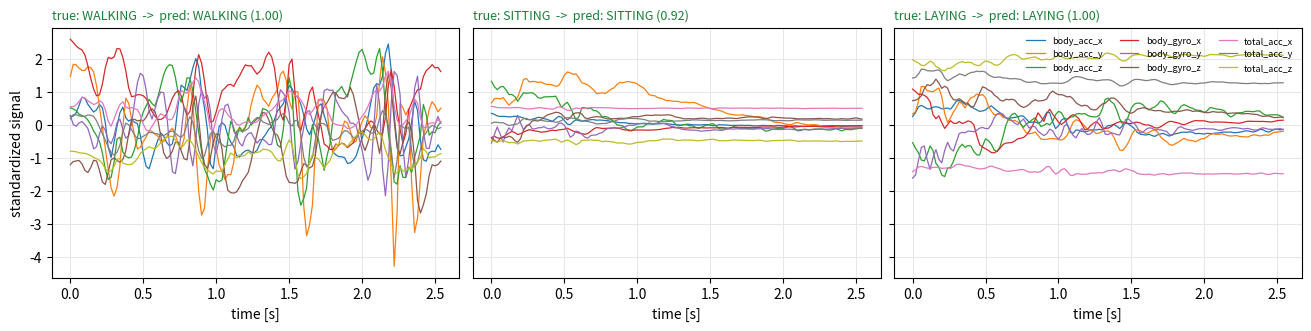

In [4]:
from data import HAR_CHANNELS
with torch.no_grad():
    pred_all = torch.cat([model(torch.as_tensor(x[i:i + 256], device=device)).argmax(-1).cpu() for i in range(0, len(x), 256)]).numpy()
print(f"seed 0 validation accuracy over all {len(y)} windows: {(pred_all == y).mean():.4f}")

prob = torch.softmax(logits, -1).cpu()
t = np.arange(x.shape[1]) / 50
show = [0, 3, 5]                                    # 아래 K 그림과 같은 window: WALKING, SITTING, LAYING
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True, sharey=True, constrained_layout=True)
for ax, w in zip(axes, show):
    i = idx[w]
    ax.plot(t, x[i], lw=0.9)
    p = int(prob[w].argmax())
    ax.set_title(f"true: {plots.CLASSES[y[i]]}  ->  pred: {plots.CLASSES[p]} ({prob[w, p]:.2f})", fontsize=9,
                 color="#1a7f37" if p == y[i] else "#cf222e", loc="left")
    ax.grid(color=plots.GRID, lw=0.7)
for ax in axes:
    ax.set_xlabel("time [s]")
axes[0].set_ylabel("standardized signal")
axes[2].legend(HAR_CHANNELS, ncol=3, fontsize=6.5, frameon=False, loc="upper right")
fig.savefig(RESULTS / "t3_input_windows.png", dpi=150)
plt.show()

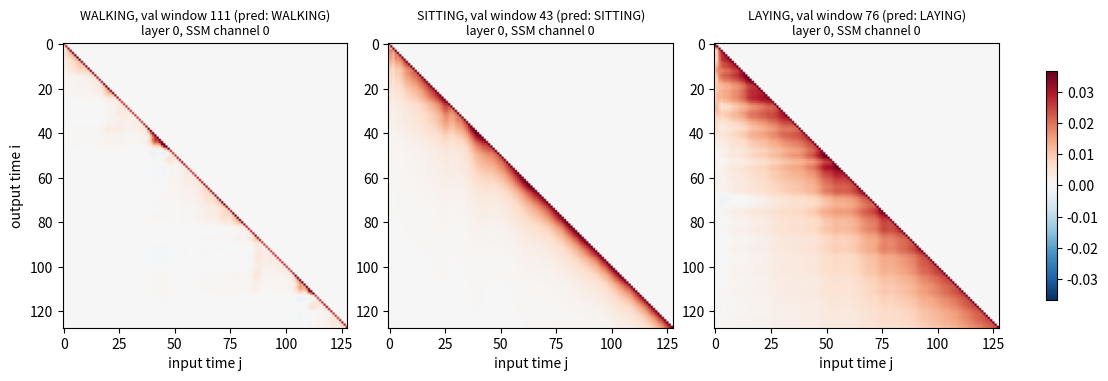

In [5]:
layer, ch = 0, 0
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), constrained_layout=True)
for ax, w in zip(axes, show):
    M = K[w, layer, ch]
    v = (M - torch.diag(torch.diagonal(M))).abs().max().item()
    im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"{plots.CLASSES[y[idx[w]]]}, val window {idx[w]} (pred: {plots.CLASSES[int(logits[w].argmax())]})\nlayer {layer}, SSM channel {ch}", fontsize=9)
    ax.set_xlabel("input time j")
axes[0].set_ylabel("output time i")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(RESULTS / "t3_kernel_matrices.png", dpi=150)
plt.show()

## 4. Class-conditional spectra와 요약 방법

시간에 따라 변하고 입력에 조건부인 커널을 다음 순서로 요약합니다 (모두 **power** $|\cdot|^2$).

1. **행 하나**: 행 $i$는 출력 시점 $i$에서 과거 입력에 적용되는 필터입니다. lag $j$로 $K[i,i-j]$, $j = 0, \dots, 63$을 쓰고($j=0$은 대각선 $K[i,i]$, $j=63$은 $K[i,i-63]$), 스펙트럼은 $S_i(f) = |\mathrm{rfft}_j K[i,i-j]|^2$ (FFT 길이 64 → 0~25 Hz의 33점, 간격 $50/64 \approx 0.78$ Hz, window 없음, 모든 조건 동일).
2. **시간**: 출력 시점 $i = 63, \dots, 127$ (65개)의 $S_i$를 산술 평균합니다. $i \ge 63$이어야 모든 행이 같은 길이 64를 갖기 때문입니다.
3. **example**: 같은 class의 validation window 전체(모든 피험자)를 산술 평균합니다.
4. **channel**: 각 layer의 SSM 채널 64개를 산술 평균합니다. 채널 번호는 seed 사이에 대응되지 않으므로 채널 평균 뒤에 seed를 비교합니다.
5. **seed**: 선은 seed 3개의 평균, 띠는 ±1 std입니다.

HAR 데이터는 이미 20 Hz low-pass filter를 거쳤으므로 점선(20 Hz) 오른쪽은 데이터가 채우지 않는 구간입니다.

In [6]:
sel = {s: load("mamba_selective", s) for s in SEEDS}
lti = {s: load("mamba_lti", s) for s in SEEDS}

def collect(name, make):
    out = []
    for s in SEEDS:
        f = RESULTS / f"{name}_seed{s}.npz"
        out.append(dict(np.load(f)) if f.exists() else make(s))
    print(f"{name:14s} windows per class: {out[0]['count']}", "(results/t3)" if (RESULTS / f"{name}_seed0.npz").exists() else "(computed here)")
    return out

HA = spectra.hidden_attention
sel_D = collect("selective_D", lambda s: spectra.class_mean_spectra(HA(sel[s][0]), x, y, max_per_class=MAX_PER_CLASS))
lti_D = collect("lti_D", lambda s: spectra.class_mean_spectra(HA(lti[s][0]), x, y, max_per_class=5))     # K does not depend on the input

selective_D    windows per class: [311 280 261 354 374 380] (results/t3)
lti_D          windows per class: [5 5 5 5 5 5] (results/t3)


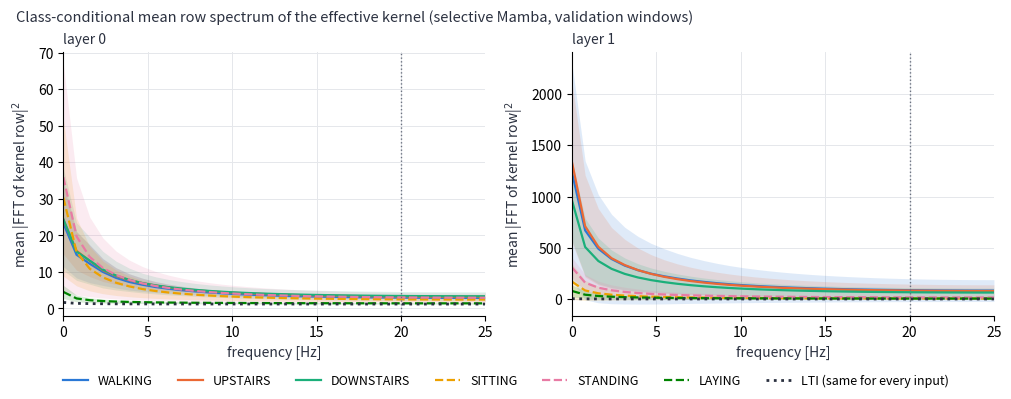

In [7]:
plots.fig_class_spectra(sel_D, lti_D)
plt.show()

**LTI와 비교**: 그림의 검은 점선은 LTI 모델의 $K$입니다. LTI는 $\Delta, B, C$가 상수라서 어떤 입력에서도 같은 커널이고, 그래서 class가 6개여도 곡선은 하나입니다. selective는 같은 layer에서 class에 따라 곡선이 갈라집니다. 단, LTI는 selective와 **따로 학습한 다른 모델**이라서 곡선의 높이 차이는 selectivity만의 효과가 아닙니다. 여기서 볼 수 있는 것은 "고정 필터는 하나, selective는 입력 종류에 따라 갈라진다"는 점까지입니다.

## 5. 확장: whole block의 Jacobian과 hidden-attention $K$의 비교

과제의 선택 확장은 "whole block에 대한 Jacobian 기반 정의를 만들고, 두 정의를 비교하라"입니다. $J$를 정의하고, $K$처럼 바로 분석하기 어려운 이유를 짚은 뒤, 가능한 범위에서 비교합니다.

**아이디어: 비선형인 block을 한 입력 근처에서만 선형으로 근사한다**

SSM 하나는 $y = Kx$로 쓸 수 있는 선형 사상이지만, block 전체는 SiLU, gate, RMSNorm 같은 비선형이 있어서 $y = f(x)$를 행렬 하나로 쓸 수 없습니다. 대신 **한 입력 $x$ 근처에서만** 보면 곡선이 거의 직선처럼 보이는 것을 이용합니다.

쉬운 예: $f(x) = x^2$은 비선형이지만 $x = 3$ 근처에서는 기울기 $6$인 직선으로 근사됩니다.
$f(3.1) = 9.61$이고, 근사 $f(3) + 6 \times 0.1 = 9.6$입니다. 이 "기울기"를 입력과 출력이 벡터일 때로 확장한 것이 **Jacobian $J$**입니다.

$$f(x + \delta) \approx f(x) + J\,\delta, \qquad J[i,o,j,c] = \frac{\partial f(x)_i[o]}{\partial x_j[c]}$$

즉 $J[i,o,j,c]$는 "입력의 $j$번째 시점, $c$번째 채널을 조금 바꾸면 출력의 $i$번째 시점, $o$번째 채널이 얼마나 변하는가"입니다. 이 값은 $x$마다 다르고(기울기가 위치마다 다르듯이), $K[i,j]$("입력 $j$가 출력 $i$에 미치는 영향")와 같은 종류의 양이라서 같은 요약을 적용해 볼 수 있습니다.

**$K$와 $J$는 다른 대상입니다**

| | $K$ (hidden attention) | $J$ (whole block) |
|---|---|---|
| 대상 | `ssm(u)` 한 단계 | block 전체 (RMSNorm, `in_proj`, `conv1d`, SiLU, SSM, gate, `out_proj`, residual) |
| 입력 → 출력 | $u \in \mathbb{R}^{L \times 64} \to y \in \mathbb{R}^{L \times 64}$ | $x \in \mathbb{R}^{L \times 32} \to \mathbb{R}^{L \times 32}$ |
| 채널 | 채널마다 독립 | `in_proj`, `x_proj`, `out_proj`, RMSNorm이 채널을 섞음 |
| 결과 shape | `[64, L, L]` (채널마다 $L \times L$) | `[L, 32, L, 32]` (채널 사이 항 포함) |
| 정확한가 | 정확: 이 입력에서 $y = Kx$ | 근사: $f(x) \ne Jx$, 입력 근처에서만 선형 |
| $\Delta, B, C$ | 이 입력의 값으로 고정 | 입력에 따라 바뀌는 효과까지 포함 |

**그래서 $K$처럼 바로 분석하기 어렵습니다**
1. $J$는 필터가 아니라 **민감도**입니다. "이 입력에 block이 적용한 필터"가 아니라 "입력을 조금 흔들 때 출력이 변하는 방식"이라서, 행 스펙트럼의 모양을 $K$처럼 "주파수 응답"으로 읽을 수 없습니다.
2. 채널이 섞여 있어서 **채널마다 $L \times L$ 필터**라는 $K$의 구조가 $J$에는 없습니다.
3. $K$는 SSM 채널 64개, $J$는 block 입출력 채널 32개라서 **채널 번호가 서로 대응되지 않습니다**.

**그래서 비교는 정의 수준에서 합니다**
- block 전체의 $J$에서 $K$와 같은 모양(`[window, layer, channel, i, j]`)을 얻으려면 채널이 같은 항 $J[i,c,j,c]$만 남겨야 하고, 그러면 채널 사이 항이 버려집니다. 아래 셀은 §3의 세 window(seed 0)에서 채널-대각 항이 $\sum J^2$에서 차지하는 비율을 계산합니다.
- 위 표의 차이를 설명하고, 수치로는 채널-대각 항이 $J$에서 차지하는 비율만 확인합니다. $J$ 스펙트럼의 모양이나 클래스별 패턴은 비교하지 않습니다.

In [8]:
model.requires_grad_(False)
inputs = jacobian.block_inputs(model, torch.as_tensor(x[[idx[w] for w in show]], device=device))   # §3의 3개 window, layer마다 block 입력
for l in range(2):
    share = []
    for k in range(len(show)):
        J = jacobian.full_jacobian(jacobian.layer_function(model, l, "block"), inputs[l][k])      # [i, o, j, c]
        diag = torch.diagonal(J, dim1=1, dim2=3)                                                 # 채널-대각 항 J[i, c, j, c]
        share.append(100 * float((diag ** 2).sum() / (J ** 2).sum()))
    print(f"layer {l}: J shape {tuple(J.shape)} = (i, o, j, c); channel-diagonal share of sum J^2 "
          f"({', '.join(plots.CLASSES[w] for w in show)}): " + ", ".join(f"{v:.0f}%" for v in share))

layer 0: J shape (128, 32, 128, 32) = (i, o, j, c); channel-diagonal share of sum J^2 (WALKING, SITTING, LAYING): 29%, 7%, 49%


layer 1: J shape (128, 32, 128, 32) = (i, o, j, c); channel-diagonal share of sum J^2 (WALKING, SITTING, LAYING): 3%, 85%, 37%


## 6. 결과 요약과 결론

seed 3개, validation 전체 window 기준입니다. 자세한 설명은 `T3_report.pdf`에 있습니다.

- **검증**: LTI에서 $K$는 starter `lti_kernel`의 Toeplitz 행렬과 반올림 수준으로 같습니다(§2).
- **모양**: 모든 class 곡선이 0 Hz에서 가장 크고 주파수가 높아질수록 작아집니다(저주파 통과 모양). class 사이의 차이는 주로 곡선의 높이입니다.
- **layer 1**: 움직이는 class(WALKING, UPSTAIRS, DOWNSTAIRS)의 곡선이 모든 주파수에서 정지 class(SITTING, STANDING, LAYING)의 곡선보다 위에 있습니다.
- **layer 0**: LAYING의 곡선이 모든 주파수에서 가장 아래에 있고, 나머지 class는 서로 가깝습니다.
- **seed 차이**: 띠(±1 std)가 넓어서, seed에 따라 크기가 많이 다릅니다.
- **LTI**: 커널이 입력과 무관해서 class와 상관없이 곡선이 하나입니다.
- **Jacobian (§5)**: whole-block $J$는 국소 선형 근사(민감도)이고 채널을 섞습니다. $K$ 모양으로 남는 채널-대각 항은 $\sum J^2$의 3–85%라서, $K$처럼 요약하지 않았습니다.

| 모델 | parameter 수 | 커널 | validation accuracy | macro-F1 |
|---|---|---|---|---|
| LTI | 15,910 | 모든 입력에서 같음 | 0.9571 ± 0.0022 | 0.9609 ± 0.0021 |
| selective | 20,454 | 입력(class)에 따라 다름 | 0.9507 ± 0.0041 | 0.9548 ± 0.0041 |

(Phase 1 결과, `scripts/evaluate_all.py`)

**결론**

- selective는 입력 적응이라는 추가 자유도를 실제로 사용합니다. 그러나 HAR validation에서 그 자유도가 더 높은 정확도로 이어지지는 않았고, 차이는 seed 변동 안이라 확인할 수 없습니다.
- **가설(검증하지 않음)**: 2.56초 window 안에서 HAR 신호의 시간 패턴이 비교적 일정해서, 고정 필터로도 충분했을 수 있습니다.
- **주의**:
  - 두 모델은 parameter 수가 다르고 따로 학습했으므로, 원인을 selectivity로 단정할 수 없습니다.
  - 이 결과는 "Mamba의 frequency response"가 아니라 입력에 조건부인 요약입니다.
  - 20 Hz 이상은 데이터가 low-pass되어 있어 해석하지 않습니다.
